# Macroeconomic Financing, Demographic Transition, and Global Maternal Mortality
## A 24-Year Longitudinal Study across 195 Countries (177-Country Balanced Panel, 2000–2023)

**Author:** Dr. Aung Chit Moe (MBBS)  
**Investigator:** MBBS Physician Transitioning into Healthcare Data Analytics  
**Primary Sources:** WHO/UN MMEIG 2025 Estimation Round • World Bank World Development Indicators (WDI)  

### Notebook Workflow
1. **Environment & Data Ingestion:** Loading the integrated analytical master dataset (`data/processed/maternal_mortality_analytical_master.csv`).
2. **Exploratory Data Analysis:** Summary benchmarks, income-group trajectories, and the Preston curve.
3. **Demographic & Health Financing Gradients:** Fertility, adolescent pregnancy, and health spending priority (% of GDP).
4. **Cross-Sectional Models (OLS):** Evaluating structural shifts across 2000, 2010, and 2023.
5. **Primary Econometric Model:** Two-Way Fixed Effects (TWFE) panel regression with country-clustered standard errors.
6. **Sensitivity Analyses:** Extreme-bound testing across MMEIG 80% Uncertainty Intervals.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Styling setup
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
sns.set_theme(style='whitegrid', palette='deep')
print('Environment initialized successfully.')

Environment initialized successfully.


In [2]:
data_path = '../data/processed/maternal_mortality_analytical_master.csv'
df = pd.read_csv(data_path)
df_bal = df[df['is_balanced_sample'] == 1].copy()

print(f'Total Grid Observations: {len(df):,} rows ({df["country_iso3"].nunique()} countries, 2000-2023)')
print(f'Balanced Analytical Sample: {len(df_bal):,} rows ({df_bal["country_iso3"].nunique()} countries)')
df_bal[['country_iso3', 'year', 'mmr_pt', 'gdp_pcap_ppp', 'chex_gdp_pct', 'tfr', 'ado_fert_rate']].head(5)

Total Grid Observations: 4,680 rows (195 countries, 2000-2023)
Balanced Analytical Sample: 4,248 rows (177 countries)


,country_iso3,year,mmr_pt,gdp_pcap_ppp,chex_gdp_pct,tfr,ado_fert_rate
24,AGO,2000,659.335188,6794.530211,1.685253,6.639,147.693
25,AGO,2001,628.606353,6846.792695,3.958827,6.601,147.253
26,AGO,2002,602.370056,7521.735988,2.939822,6.567,150.196
27,AGO,2003,538.016775,7516.813915,3.106803,6.533,152.242
28,AGO,2004,498.908969,8079.526133,3.460840,6.499,155.118


## 1. Descriptive Benchmarks Across Decades (2000 vs 2010 vs 2015 vs 2023)

In [3]:
bench_summary = df_bal.groupby('year').agg({
    'mmr_pt': ['mean', 'median', 'std'],
    'gdp_pcap_ppp': ['mean', 'median'],
    'chex_gdp_pct': ['mean', 'median'],
    'tfr': ['mean', 'median'],
    'maternal_deaths': 'sum'
}).loc[[2000, 2010, 2015, 2023]]

bench_summary.round(2)

mmr_pt                gdp_pcap_ppp  ... chex_gdp_pct   tfr        maternal_deaths
        mean median     std         mean  ...       median  mean median             sum
year                                      ...                                          
2000  217.74  67.64  303.18     18470.57  ...         4.87  3.22   2.74       408410.42
2010  176.34  54.74  258.39     21938.21  ...         5.49  2.92   2.38       332630.71
2015  144.16  48.08  212.24     23344.57  ...         6.07  2.77   2.27       295130.49
2023  109.57  42.11  157.98     26119.30  ...         6.53  2.42   1.98       228446.62

[4 rows x 10 columns]

In [4]:
df_2023 = df_bal[df_bal['year'] == 2023].copy()
inc_summary_2023 = df_2023.groupby('income_level_name').agg(
    n_countries=('country_iso3', 'count'),
    mean_mmr=('mmr_pt', 'mean'),
    median_mmr=('mmr_pt', 'median'),
    mean_gdp_ppp=('gdp_pcap_ppp', 'mean'),
    mean_chex_pct=('chex_gdp_pct', 'mean'),
    mean_tfr=('tfr', 'mean'),
    mean_ado_fert=('ado_fert_rate', 'mean')
).loc[['Low income', 'Lower middle income', 'Upper middle income', 'High income']]
inc_summary_2023.round(2)

,n_countries,mean_mmr,median_mmr,mean_gdp_ppp,mean_chex_pct,mean_tfr,mean_ado_fert
income_level_name,,,,,,,
Low income,18,370.10,353.96,2176.96,5.95,4.62,103.29
Lower middle income,43,192.06,138.86,6705.76,5.36,3.22,63.99
Upper middle income,54,60.47,45.79,17581.84,6.80,2.06,34.77
High income,62,19.48,7.67,53970.38,8.09,1.53,14.03


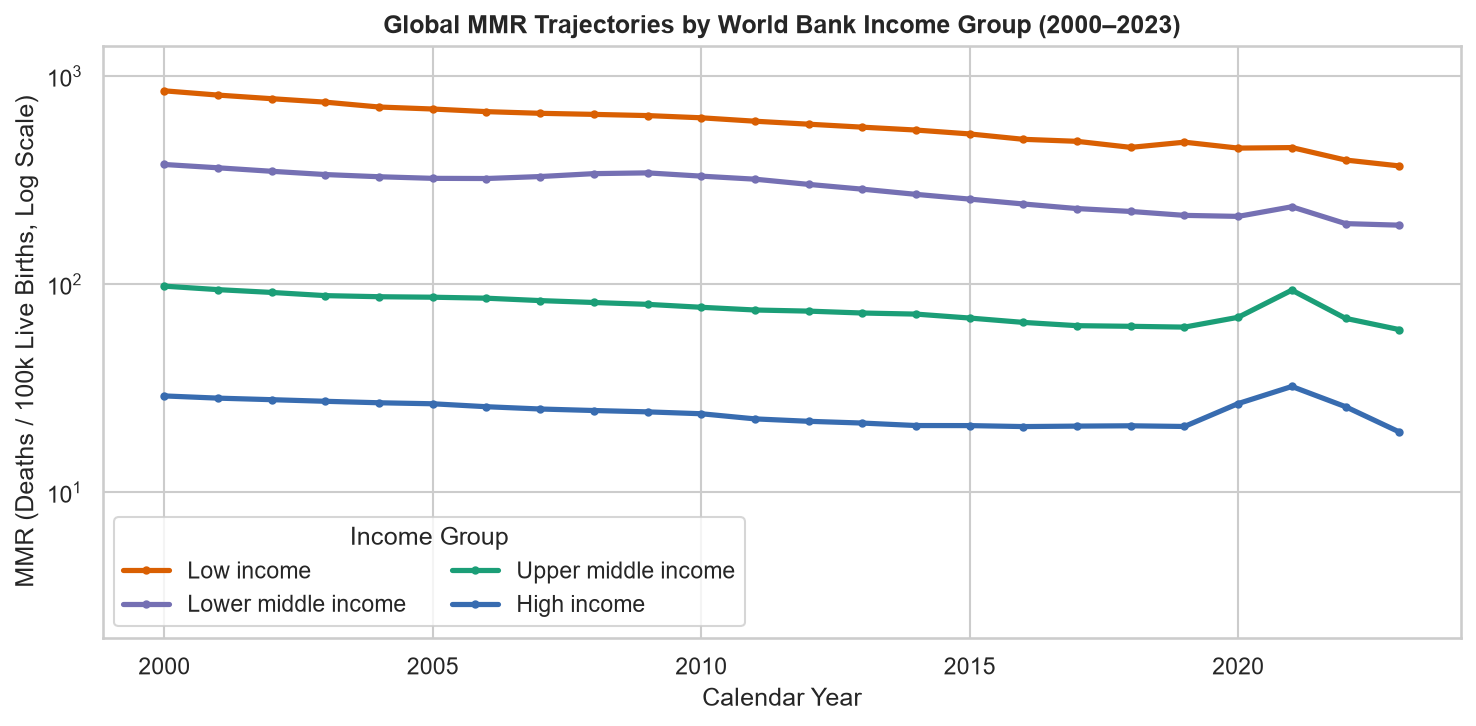

In [5]:
# Plotting MMR Trajectories by Income Tier
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
palette = {'Low income': '#d95f02', 'Lower middle income': '#7570b3', 'Upper middle income': '#1b9e77', 'High income': '#386cb0'}

fig, ax = plt.subplots(figsize=(10, 5))
traj = df_bal.groupby(['year', 'income_level_name'])['mmr_pt'].mean().reset_index()
for inc in income_order:
    sub_traj = traj[traj['income_level_name'] == inc]
    ax.plot(sub_traj['year'], sub_traj['mmr_pt'], label=inc, color=palette[inc], linewidth=2.5, marker='o', markersize=3)

ax.set_yscale('log')
ax.set_ylim(2, 1400)
ax.set_title('Global MMR Trajectories by World Bank Income Group (2000–2023)', fontsize=12, fontweight='bold')
ax.set_xlabel('Calendar Year')
ax.set_ylabel('MMR (Deaths / 100k Live Births, Log Scale)')
ax.legend(title='Income Group', loc='lower left', ncol=2)
plt.tight_layout()
plt.show()

## 1B. The Preston Curve of Maternal Survival (Figure 2)
Evaluating the non-linear diminishing returns relationship between constant-price PPP GDP per capita and Maternal Mortality Ratio (2023), strictly decoupled from Health Expenditure (% of GDP).

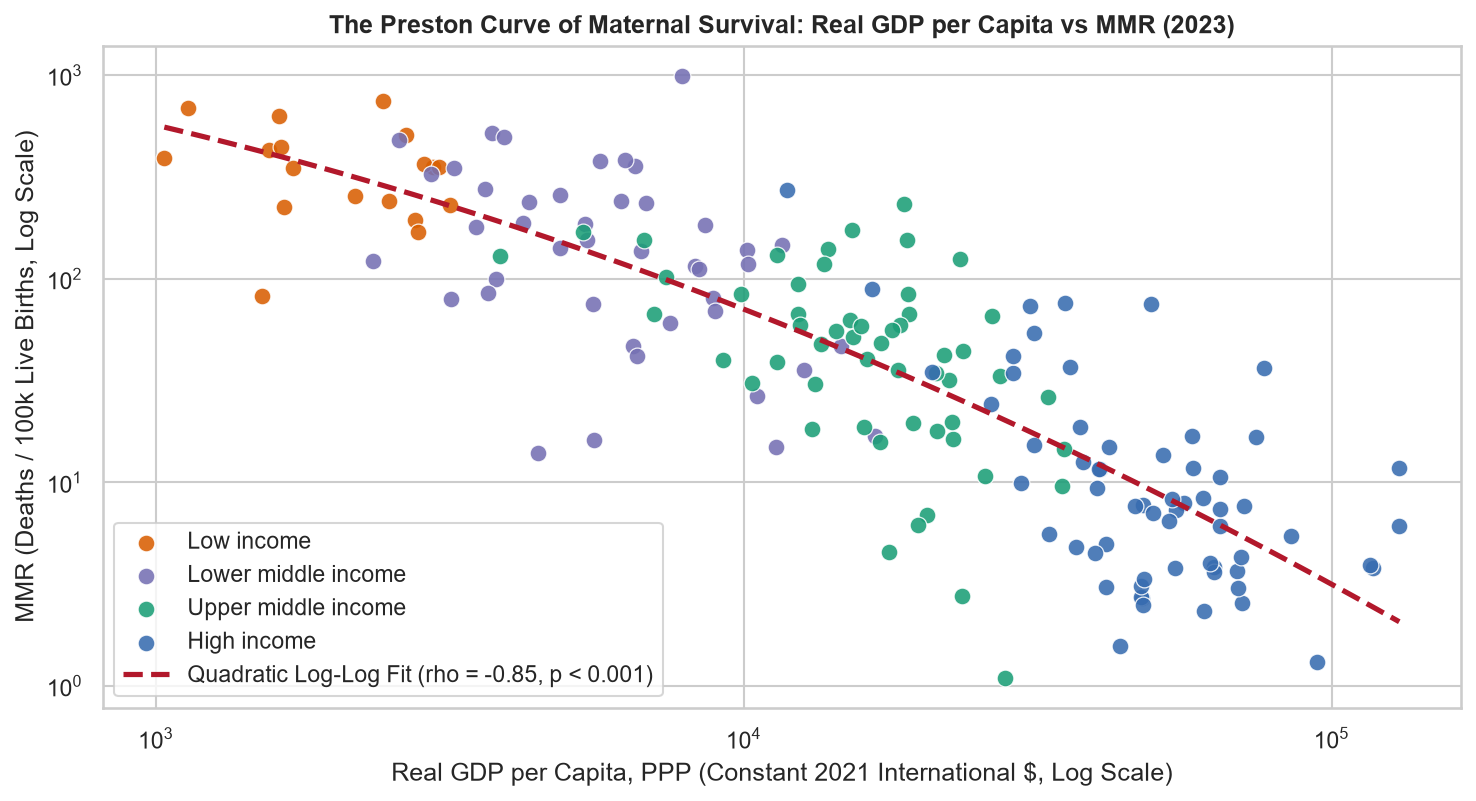

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for inc in income_order:
    sub = df_2023[df_2023['income_level_name'] == inc]
    ax.scatter(sub['gdp_pcap_ppp'], sub['mmr_pt'], color=palette[inc], label=inc, s=65, alpha=0.88, edgecolors='white', linewidth=0.6)

z = np.polyfit(df_2023['log_gdp_pcap_ppp'], df_2023['log_mmr_pt'], 2)
p = np.poly1d(z)
x_vals = np.linspace(df_2023['log_gdp_pcap_ppp'].min(), df_2023['log_gdp_pcap_ppp'].max(), 100)
ax.plot(np.exp(x_vals), np.exp(p(x_vals)), color='#b2182b', linewidth=2.5, linestyle='--', label='Quadratic Log-Log Fit (rho = -0.85, p < 0.001)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('The Preston Curve of Maternal Survival: Real GDP per Capita vs MMR (2023)', fontweight='bold')
ax.set_xlabel('Real GDP per Capita, PPP (Constant 2021 International $, Log Scale)')
ax.set_ylabel('MMR (Deaths / 100k Live Births, Log Scale)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 2. Demographic Transition & Adolescent Pregnancy (Figure 6)
Evaluating Total Fertility Rate (TFR) and Adolescent Fertility Rate vs Maternal Mortality Ratio (2023).

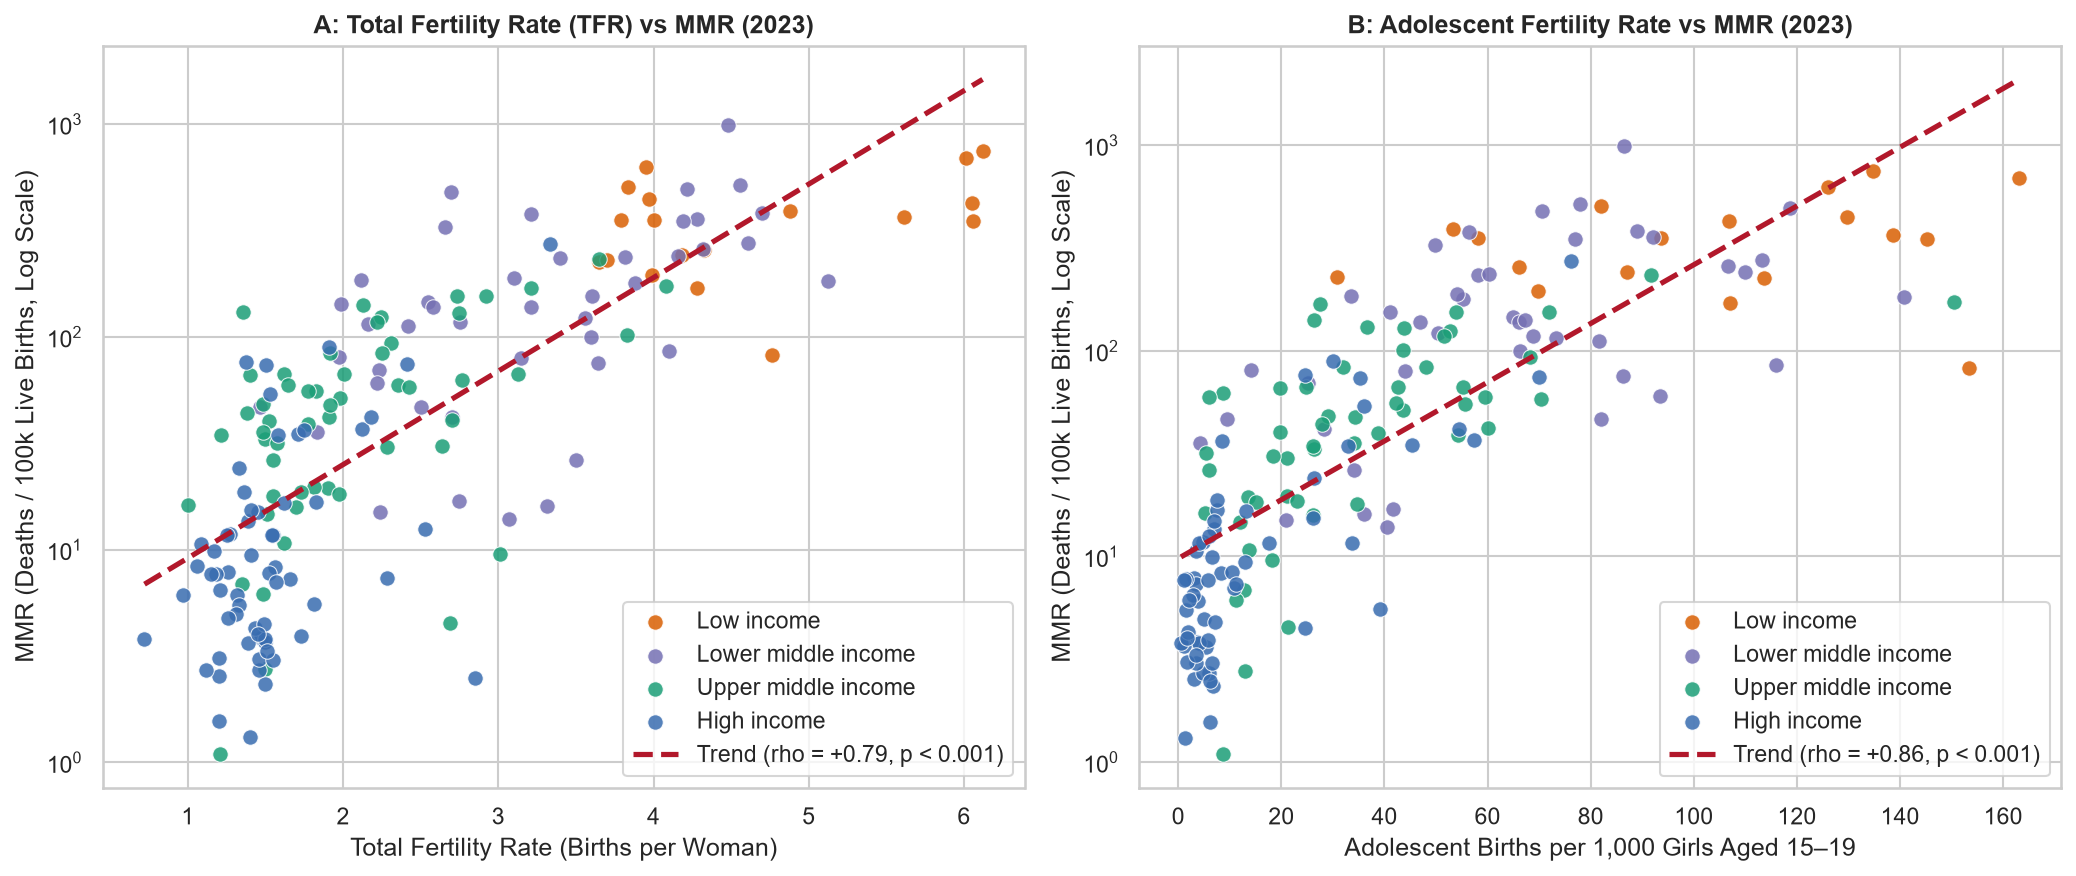

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for inc in income_order:
    sub = df_2023[df_2023['income_level_name'] == inc]
    ax1.scatter(sub['tfr'], sub['mmr_pt'], color=palette[inc], label=inc, s=55, alpha=0.85, edgecolors='white', linewidth=0.5)
    ax2.scatter(sub['ado_fert_rate'], sub['mmr_pt'], color=palette[inc], label=inc, s=55, alpha=0.85, edgecolors='white', linewidth=0.5)

# Fit curves
p1 = np.polyfit(df_2023['tfr'], df_2023['log_mmr_pt'], 1)
x1 = np.linspace(df_2023['tfr'].min(), df_2023['tfr'].max(), 100)
ax1.plot(x1, np.exp(p1[0]*x1 + p1[1]), color='#b2182b', linewidth=2.5, linestyle='--', label='Trend (rho = +0.79, p < 0.001)')

p2 = np.polyfit(df_2023['ado_fert_rate'], df_2023['log_mmr_pt'], 1)
x2 = np.linspace(df_2023['ado_fert_rate'].min(), df_2023['ado_fert_rate'].max(), 100)
ax2.plot(x2, np.exp(p2[0]*x2 + p2[1]), color='#b2182b', linewidth=2.5, linestyle='--', label='Trend (rho = +0.86, p < 0.001)')

ax1.set_yscale('log')
ax1.set_title('A: Total Fertility Rate (TFR) vs MMR (2023)', fontweight='bold')
ax1.set_xlabel('Total Fertility Rate (Births per Woman)')
ax1.set_ylabel('MMR (Deaths / 100k Live Births, Log Scale)')
ax1.legend(loc='lower right')

ax2.set_yscale('log')
ax2.set_title('B: Adolescent Fertility Rate vs MMR (2023)', fontweight='bold')
ax2.set_xlabel('Adolescent Births per 1,000 Girls Aged 15–19')
ax2.set_ylabel('MMR (Deaths / 100k Live Births, Log Scale)')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 3. Domestic Health Financing Priority (% of GDP) Decoupled from GDP (Figure 7)
Showing Health Expenditure (% of GDP) vs MMR and median MMR across spending priority quartiles.

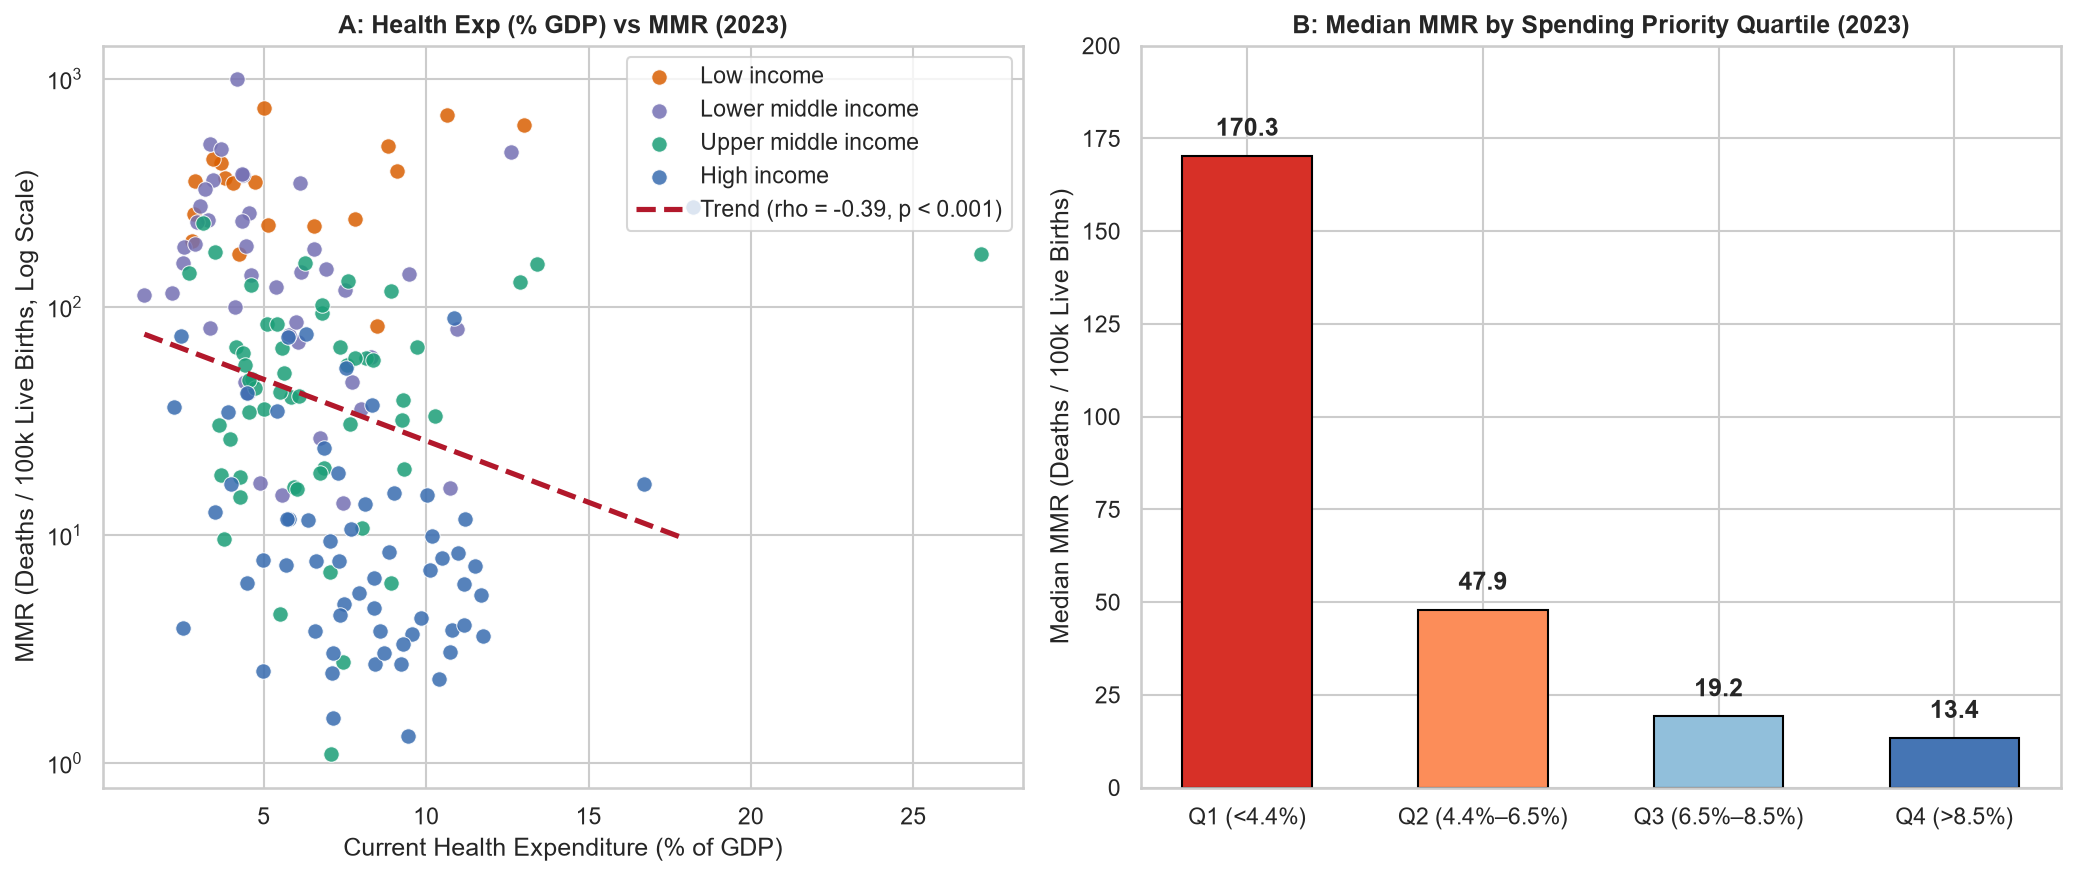

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for inc in income_order:
    sub = df_2023[df_2023['income_level_name'] == inc]
    ax1.scatter(sub['chex_gdp_pct'], sub['mmr_pt'], color=palette[inc], label=inc, s=55, alpha=0.85, edgecolors='white', linewidth=0.5)

p_chex = np.polyfit(df_2023['chex_gdp_pct'], df_2023['log_mmr_pt'], 1)
xc = np.linspace(df_2023['chex_gdp_pct'].min(), 18, 100)
ax1.plot(xc, np.exp(p_chex[0]*xc + p_chex[1]), color='#b2182b', linewidth=2.5, linestyle='--', label='Trend (rho = -0.39, p < 0.001)')
ax1.set_yscale('log')
ax1.set_title('A: Health Exp (% GDP) vs MMR (2023)', fontweight='bold')
ax1.set_xlabel('Current Health Expenditure (% of GDP)')
ax1.set_ylabel('MMR (Deaths / 100k Live Births, Log Scale)')
ax1.legend(loc='upper right')

# Quartiles Bar
df_2023['chex_q'] = pd.qcut(df_2023['chex_gdp_pct'], 4, labels=['Q1 (<4.4%)', 'Q2 (4.4%–6.5%)', 'Q3 (6.5%–8.5%)', 'Q4 (>8.5%)'])
q_med = df_2023.groupby('chex_q', observed=False)['mmr_pt'].median().reset_index()
bars = ax2.bar(q_med['chex_q'], q_med['mmr_pt'], color=['#d73027', '#fc8d59', '#91bfdb', '#4575b4'], width=0.55, edgecolor='black')
for b in bars:
    ax2.text(b.get_x() + b.get_width()/2., b.get_height() + 4, f'{b.get_height():.1f}', ha='center', va='bottom', fontweight='bold')
ax2.set_title('B: Median MMR by Spending Priority Quartile (2023)', fontweight='bold')
ax2.set_ylabel('Median MMR (Deaths / 100k Live Births)')
ax2.set_ylim(0, 200)

plt.tight_layout()
plt.show()

## 4. Cross-Sectional OLS Regressions (2000, 2010, 2023)
Model specification:
$$\ln(\text{MMR}_i) = \beta_0 + \beta_1 \ln(\text{GDP}_i) + \beta_2 \text{HealthExp}_i + \beta_3 \text{TFR}_i + \beta_4 \text{AdoFert}_i + \beta_5 \text{Urban}_i + \epsilon_i$$

In [9]:
for y in [2000, 2010, 2023]:
    sub_y = df_bal[df_bal['year'] == y]
    m = smf.ols('log_mmr_pt ~ log_gdp_pcap_ppp + chex_gdp_pct + tfr + ado_fert_rate + urban_pct', data=sub_y).fit(cov_type='HC1')
    print(f'=== OLS REGRESSION YEAR {y} (R-squared: {m.rsquared:.3f}) ===')
    print(m.summary().tables[1])
    print()

=== OLS REGRESSION YEAR 2000 (R-squared: 0.832) ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            8.0742      0.799     10.110      0.000       6.509       9.640
log_gdp_pcap_ppp    -0.5322      0.090     -5.933      0.000      -0.708      -0.356
chex_gdp_pct        -0.0302      0.028     -1.083      0.279      -0.085       0.025
tfr                  0.2616      0.051      5.117      0.000       0.161       0.362
ado_fert_rate        0.0090      0.002      5.217      0.000       0.006       0.012
urban_pct           -0.0022      0.004     -0.568      0.570      -0.010       0.005

=== OLS REGRESSION YEAR 2010 (R-squared: 0.802) ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            9.3728      1.030      9

## 5. Primary Longitudinal Model: Two-Way Fixed Effects (TWFE)
Controlling for unobserved time-invariant country fixed effects and secular global time shocks:
$$\ln(\text{MMR}_{it}) = \alpha_i + \gamma_t + \beta_1 \ln(\text{GDP}_{it}) + \beta_2 \text{HealthExp}_{it} + \beta_3 \text{TFR}_{it} + \beta_4 \text{AdoFert}_{it} + \beta_5 \text{Urban}_{it} + \epsilon_{it}$$

In [10]:
# Two-Way Fixed Effects on balanced panel (177 countries, 24 years, n = 4,248)
core_vars = ['log_gdp_pcap_ppp', 'chex_gdp_pct', 'tfr', 'ado_fert_rate', 'urban_pct']
twfe_formula = 'log_mmr_pt ~ log_gdp_pcap_ppp + chex_gdp_pct + tfr + ado_fert_rate + urban_pct + C(country_iso3) + C(year)'
m_twfe_pt = smf.ols(twfe_formula, data=df_bal).fit(cov_type='cluster', cov_kwds={'groups': df_bal['country_iso3']})

print('=== PRIMARY TWO-WAY FIXED EFFECTS RESULTS (CRV1 Clustered SE, n = 4,248) ===')
twfe_summary = pd.DataFrame({
    'Coef': m_twfe_pt.params[core_vars],
    'Cluster_SE': m_twfe_pt.bse[core_vars],
    'z_stat': m_twfe_pt.tvalues[core_vars],
    'p_value': m_twfe_pt.pvalues[core_vars]
})
twfe_summary.round(4)

=== PRIMARY TWO-WAY FIXED EFFECTS RESULTS (CRV1 Clustered SE, n = 4,248) ===


,Coef,Cluster_SE,z_stat,p_value
log_gdp_pcap_ppp,-0.4959,0.0768,-6.4567,0.0000
chex_gdp_pct,0.0110,0.0067,1.6298,0.1031
tfr,0.1308,0.0624,2.0955,0.0361
ado_fert_rate,-0.0007,0.0021,-0.3433,0.7313
urban_pct,-0.0045,0.0037,-1.2322,0.2179


## 6. Sensitivity Analyses: 80% Uncertainty Bounds Re-Estimation
Testing whether our findings are invariant to MMEIG's lower 10th percentile (`0.1`) and upper 90th percentile (`0.9`) bounds.

In [11]:
m_low = smf.ols('log_mmr_low ~ log_gdp_pcap_ppp + chex_gdp_pct + tfr + ado_fert_rate + urban_pct + C(country_iso3) + C(year)',
                data=df_bal).fit(cov_type='cluster', cov_kwds={'groups': df_bal['country_iso3']})
m_high = smf.ols('log_mmr_high ~ log_gdp_pcap_ppp + chex_gdp_pct + tfr + ado_fert_rate + urban_pct + C(country_iso3) + C(year)',
                 data=df_bal).fit(cov_type='cluster', cov_kwds={'groups': df_bal['country_iso3']})

sens_df = pd.DataFrame({
    'Variable': ['ln(GDP PPP)', 'Health Exp % GDP', 'Total Fertility', 'Adolescent Fert', 'Urban %'],
    'Point Estimate (0.5)': [m_twfe_pt.params[v] for v in core_vars],
    'Lower Bound (0.1)': [m_low.params[v] for v in core_vars],
    'Upper Bound (0.9)': [m_high.params[v] for v in core_vars]
})
sens_df.round(4)

,Variable,Point Estimate (0.5),Lower Bound (0.1),Upper Bound (0.9)
0,ln(GDP PPP),-0.4959,-0.4943,-0.4773
1,Health Exp % GDP,0.0110,0.0111,0.0107
2,Total Fertility,0.1308,0.1110,0.1331
3,Adolescent Fert,-0.0007,-0.0013,-0.0003
4,Urban %,-0.0045,-0.0030,-0.0051
